# Homework 4: Advanced Regression and Logistic Regression

**Name:** Md. Aslam Hossain  
**UAH Email:** mh0708@uah.edu \
**Course:** CPE 586 Fall 2026 \
**Unique Keyword:** tornadochildd\
**GitHub Account:** https://github.com/tornadochilddgh \
**GitHub Repository:** https://github.com/tornadochilddgh/tornadochildd \
**PyPI Release** https://pypi.org/project/tornadochildd/0.1.6/ \
**Commit Hash** 4d03b312cb711486b5c23e6d8aa8d589937d6c88

## Question 1: Locally Weighted Regression

The objective function is

$$
J(w)=\frac{1}{2}\sum_{i=1}^{N}a^{(i)}
\left(y^{(i)}-w^Tx^{(i)}\right)^2
+\frac{\lambda}{2}\|w\|^2.
$$

Let $X\in\mathbb{R}^{N\times D}$ be the design matrix, with
row $i$ equal to $(x^{(i)})^T$, and let
$A=\operatorname{diag}(a^{(1)},\ldots,a^{(N)})$.

### Solution

The objective can be written in matrix form as

$$
J(w)=\frac{1}{2}(y-Xw)^TA(y-Xw)
+\frac{\lambda}{2}w^Tw.
$$

Since $A$ is symmetric, expanding gives

$$
J(w)=\frac{1}{2}y^TAy-w^TX^TAy
+\frac{1}{2}w^TX^TAXw+\frac{\lambda}{2}w^Tw.
$$

Differentiating with respect to $w$,

$$
\nabla_wJ(w)=-X^TAy+X^TAXw+\lambda w.
$$

Setting the gradient equal to zero at $w=\hat{w}$,

$$
X^TAX\hat{w}+\lambda\hat{w}=X^TAy.
$$

Therefore,

$$
(X^TAX+\lambda I)\hat{w}=X^TAy,
$$

which gives

$$
\boxed {\hat{w}=(X^TAX+\lambda I)^{-1}X^TAy.}
$$

For positive weights and $\lambda>0$, the Hessian
$X^TAX+\lambda I$ is positive definite, so this is the unique
global minimum. If $\lambda=0$, the inverse exists when $X$
has full column rank.

There is no $1/N$ factor because the objective uses the total
loss rather than the average loss.

## Question 2: Logistic Regression by Hand

The dataset and parameter vector are

$$
X=
\begin{bmatrix}
0&0&1\\
0&1&0\\
0&1&1\\
1&0&0
\end{bmatrix},
\qquad
y=
\begin{bmatrix}
0\\1\\1\\0
\end{bmatrix},
\qquad
\theta=
\begin{bmatrix}
1.5\\2\\1
\end{bmatrix}.
$$

There is no intercept term. The logistic hypothesis is

$$
h_\theta(x)=\frac{1}{1+e^{-\theta^Tx}}.
$$

The linear scores are

$$
X\theta=
\begin{bmatrix}
1\\2\\3\\1.5
\end{bmatrix}.
$$

Therefore, the predicted probabilities are

<table align="center" style="margin-left: auto; margin-right: auto; text-align: center;">
  <tr>
    <th>Sample i</th>
    <th>y⁽ⁱ⁾</th>
    <th>θᵀx⁽ⁱ⁾</th>
    <th>hθ(x⁽ⁱ⁾)</th>
  </tr>
  <tr><td>1</td><td>0</td><td>1.0000</td><td>0.7311</td></tr>
  <tr><td>2</td><td>1</td><td>2.0000</td><td>0.8808</td></tr>
  <tr><td>3</td><td>1</td><td>3.0000</td><td>0.9526</td></tr>
  <tr><td>4</td><td>0</td><td>1.5000</td><td>0.8176</td></tr>
</table>

All calculations below use unrounded probabilities; final numerical
answers are rounded to four decimal places.

### 1. Average Negative Log-Likelihood

$$
J(\theta)=-\frac{1}{4}\sum_{i=1}^{4}
\left[
y^{(i)}\ln h_\theta(x^{(i)})
+(1-y^{(i)})\ln(1-h_\theta(x^{(i)}))
\right].
$$

Using the labels $0,1,1,0$,

$$
J(\theta)=-\frac{1}{4}
\left[
\ln(1-h_1)+\ln(h_2)+\ln(h_3)+\ln(1-h_4)
\right],
$$

where $h_i=h_\theta(x^{(i)})$.

Equivalently,

$$
J(\theta)=\frac{1}{4}
\left[
\ln(1+e^1)+\ln(1+e^{-2})
+\ln(1+e^{-3})+\ln(1+e^{1.5})
\right].
$$

Thus,

$$
\boxed{J(\theta)=0.7975.}
$$

### 2. Gradients

For each parameter,

$$
\frac{\partial J}{\partial\theta_j}
=\frac{1}{4}\sum_{i=1}^{4}
(h_i-y^{(i)})x_j^{(i)}.
$$

The first feature is nonzero only for sample 4:

$$
\frac{\partial J}{\partial\theta_1}
=\frac{1}{4}(h_4-0)
=\boxed{0.2044}.
$$

The second feature is nonzero for samples 2 and 3:

$$
\frac{\partial J}{\partial\theta_2}
=\frac{1}{4}\left[(h_2-1)+(h_3-1)\right]
=\boxed{-0.0417}.
$$

The third feature is nonzero for samples 1 and 3:

$$
\frac{\partial J}{\partial\theta_3}
=\frac{1}{4}\left[(h_1-0)+(h_3-1)\right]
=\boxed{0.1709}.
$$

Therefore,

$$
\boxed{
\nabla_\theta J=
\begin{bmatrix}
0.2044\\
-0.0417\\
0.1709
\end{bmatrix}.
}
$$

### 3. Parameter Update

With learning rate $\eta=1$, update all parameters simultaneously:

$$
\theta_{\mathrm{new}}=\theta-\eta\nabla_\theta J.
$$

Using the unrounded gradients gives

$$
\boxed{
\theta_{\mathrm{new}}=
\begin{bmatrix}
1.2956\\
2.0417\\
0.8291
\end{bmatrix}.
}
$$

## Question 3: Logistic Regression vs. Polynomial Regression

**Logistic regression** is used for classification. In binary classification,
it models the probability that an observation belongs to class 1 using
the sigmoid function:

$$
P(y=1\mid x)=\frac{1}{1+e^{-z}},
\qquad
z=\theta_0+\theta_1x_1+\cdots+\theta_Dx_D.
$$

The predicted probability lies between 0 and 1. A threshold, commonly
0.5, converts this probability into a class label. The model is typically
trained by minimizing cross-entropy loss.

**Polynomial regression** is used to predict a continuous numerical
response. For a single input variable, a degree-$p$ model is

$$
\hat{y}=\beta_0+\beta_1x+\beta_2x^2+\cdots+\beta_px^p.
$$

Its predictions are not restricted to the interval from 0 to 1.
It is typically fitted by minimizing the sum of squared errors.
Although the relationship is polynomial in $x$, the model is linear
in its coefficients.

Thus, logistic regression predicts class probabilities, while
polynomial regression predicts continuous values using polynomial
features. Polynomial features can also be used in logistic regression
to obtain a nonlinear decision boundary.

## Question 4: Assumptions and Diagnostics in Linear Regression

### 1. Detecting a Violation of Homoscedasticity

Homoscedasticity means that the errors have constant conditional variance:

$$
\operatorname{Var}(\varepsilon_i\mid X)=\sigma^2.
$$

To assess this assumption, plot the residuals against the fitted values.
A roughly constant vertical spread around zero supports homoscedasticity.
A funnel-shaped pattern, where the spread increases or decreases,
suggests heteroscedasticity.

A formal check is the **Breusch–Pagan test**, whose null hypothesis is
constant error variance. A small p-value, such as $p<0.05$, provides
evidence against homoscedasticity.

### 2. Detecting a Violation of Normality of Errors

Use a **normal Q–Q plot** of the residuals. Approximately normally
distributed errors produce points close to a straight line.
Systematic curvature or large departures in the tails suggest
non-normality.

A residual histogram can also reveal skewness or unusually heavy tails.
A formal normality test, such as the **Jarque–Bera test**, provides
additional evidence.

### 3. Detecting Multicollinearity

Multicollinearity occurs when one predictor is approximately a linear
combination of other predictors. It can make coefficient estimates
unstable and increase their standard errors.

Inspect the predictor correlation matrix for strong pairwise
correlations. However, pairwise correlations alone may miss dependence
involving several predictors.

A more informative measure is the **variance inflation factor**:

$$
\operatorname{VIF}_j=\frac{1}{1-R_j^2},
$$

where $R_j^2$ is obtained by regressing predictor $x_j$ on all the
remaining predictors, including an intercept.

A VIF near 1 indicates little multicollinearity. Values above 5 warrant
attention, and values above 10 commonly indicate serious
multicollinearity. These are guidelines rather than strict cutoffs.

### 4. Bonus: Testing for Dependence of Errors

For observations with a meaningful time order, the **Durbin–Watson
test** checks for first-order serial correlation in the errors.

Consider the error model

$$
\varepsilon_t=\rho\varepsilon_{t-1}+u_t,
$$

where $u_t$ is an uncorrelated innovation. The hypotheses are

$$
H_0:\rho=0,
\qquad
H_1:\rho\ne0.
$$

Using the fitted residuals $e_t=y_t-\hat{y}_t$, the test statistic is

$$
d=
\frac{\sum_{t=2}^{n}(e_t-e_{t-1})^2}
{\sum_{t=1}^{n}e_t^2}.
$$

The statistic lies between 0 and 4 and approximately satisfies

$$
d\approx2(1-\hat{\rho}).
$$

Its interpretation is:

- $d$ near 2 suggests little first-order autocorrelation.
- $d$ substantially below 2 suggests positive autocorrelation.
- $d$ substantially above 2 suggests negative autocorrelation.

For a formal decision, compare the statistic with the appropriate
Durbin–Watson critical bounds. For a positive-autocorrelation test,
$d<d_L$ leads to rejection of $H_0$, while $d>d_U$ leads to failure
to reject $H_0$. Values between $d_L$ and $d_U$ are inconclusive.
Negative autocorrelation can be assessed using $4-d$; a two-sided
test must account for both tails.

This test detects first-order serial correlation, not every possible
form of dependence. The standard test is also unsuitable when a
lagged dependent variable is included as a predictor; a
Breusch–Godfrey test is an alternative.

### 5. Bonus: Testing for Non-Normal Errors

The **Jarque–Bera test** assesses normality using residual skewness
and kurtosis.

The null hypothesis is that the errors are normally distributed;
the alternative is that they are not normally distributed.

Define the residual central moments as

$$
m_k=\frac{1}{n}\sum_{i=1}^{n}(e_i-\bar{e})^k.
$$

The sample skewness and kurtosis are

$$
S=\frac{m_3}{m_2^{3/2}},
\qquad
K=\frac{m_4}{m_2^2}.
$$

A normal distribution has skewness 0 and kurtosis 3.
The Jarque–Bera statistic is

$$
JB=\frac{n}{6}
\left[S^2+\frac{(K-3)^2}{4}\right].
$$

Under the null hypothesis and suitable regularity conditions, its
large-sample distribution is

$$
JB\overset{a}{\sim}\chi_2^2.
$$

At the 5% significance level, reject normality if

$$
JB>5.991,
$$

or equivalently if the p-value is below 0.05.

A significant result indicates evidence of non-normality through
skewness, kurtosis, or both. Failure to reject does not prove
normality, so the test should be considered alongside a Q–Q plot.

In [1]:
import sys
import shutil

if shutil.which("uv"):
    !uv pip install --python "{sys.executable}" tornadochildd==0.1.6
else:
    %pip install tornadochildd==0.1.6

Using Python 3.12.14 environment at: /home/md-aslam-hossain/tornadochildd/.venv
Checked 1 package in 20ms


In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import statsmodels as sm
import openpyxl

print("Python executable:", sys.executable)
print("PyTorch version:", torch.__version__)
print("All required imports succeeded.")

Python executable: /home/md-aslam-hossain/tornadochildd/.venv/bin/python
PyTorch version: 2.14.0+cu130
All required imports succeeded.


## Question 5: Multiple Regression Using Cauchy Loss

The objective is to predict the power plant's net hourly electrical
output, PE (MW), using four input features:

- **AT:** Ambient temperature (°C).
- **V:** Exhaust vacuum (cm Hg).
- **AP:** Ambient pressure (mbar).
- **RH:** Relative humidity (%).

The regression model is

$$
\widehat{PE}=w_0+w_1AT+w_2V+w_3AP+w_4RH.
$$

We implement a `CauchyRegression` class using PyTorch and fit the
model by minimizing the mean Cauchy loss:

$$
L(w)=\frac{1}{N}\sum_{i=1}^{N}
\frac{c^2}{2}
\ln\left[
1+\left(\frac{y_i-\hat{y}_i}{c}\right)^2
\right],
\qquad c=1.
$$

Cauchy loss grows more slowly than squared error for large residuals,
reducing the influence of observations with unusually large errors.

**Dataset source:**  
https://github.com/rahulbhadani/Datasets/tree/master/CombinedCyclePowerPlant

In [3]:
data_url = (
    "https://raw.githubusercontent.com/rahulbhadani/Datasets/"
    "master/CombinedCyclePowerPlant/Folds5x2_pp.csv"
)

df = pd.read_csv(data_url)

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())

print("\nMissing values per column:")
print(df.isna().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

Dataset shape: (9568, 5)
Column names: ['AT', 'V', 'AP', 'RH', 'PE']


,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43



Missing values per column:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

Number of duplicate rows: 41


In [4]:
import inspect
from tornadochildd.model.regression import CauchyRegression

print("Class imported successfully.")
print("Loaded from:", inspect.getfile(CauchyRegression))

Class imported successfully.
Loaded from: /home/md-aslam-hossain/tornadochildd/.venv/lib/python3.12/site-packages/tornadochildd/model/regression.py


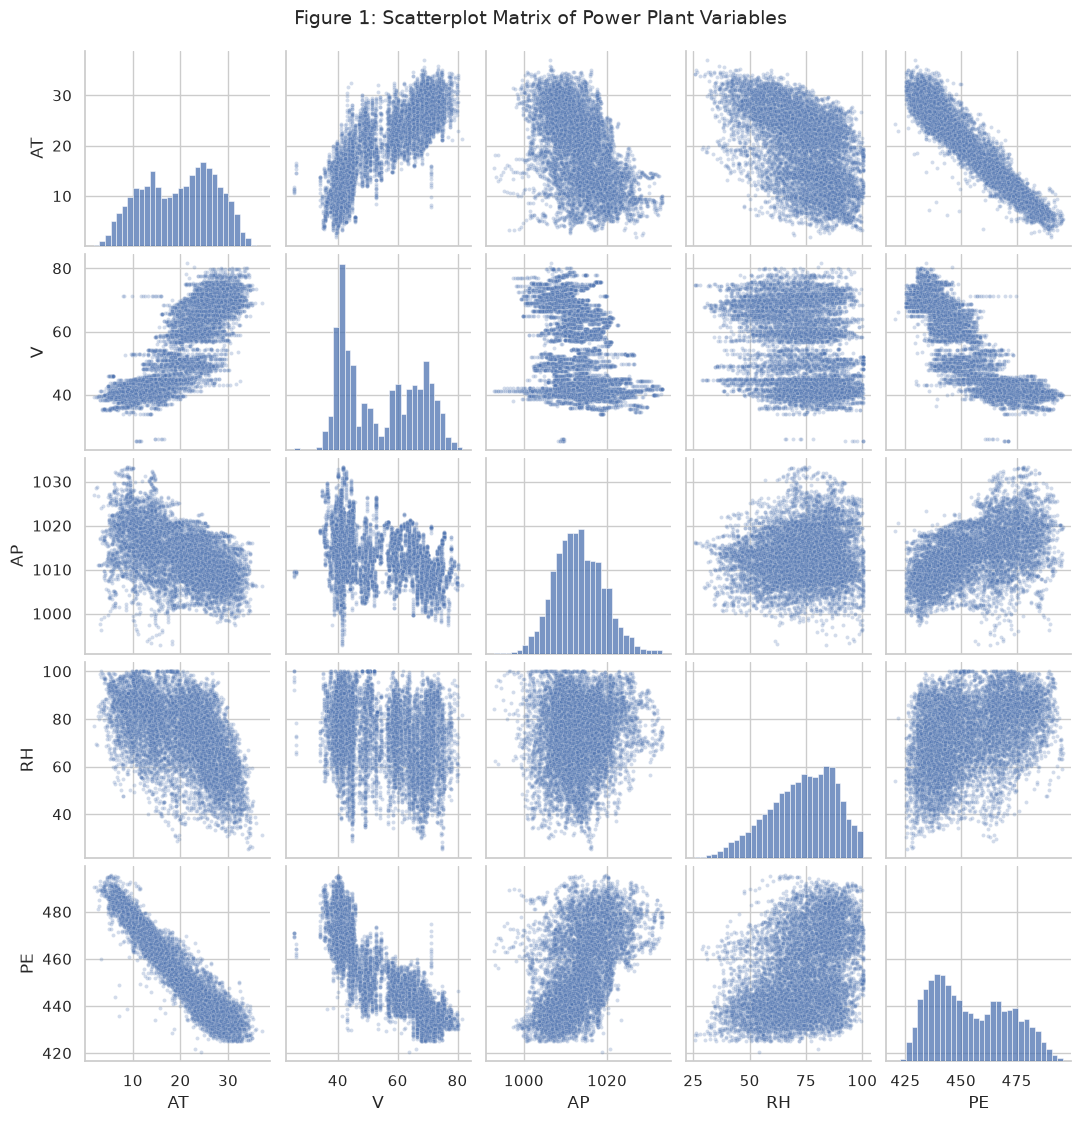

In [5]:
sns.set_theme(style="whitegrid")

columns = ["AT", "V", "AP", "RH", "PE"]

g = sns.pairplot(
    df[columns],
    diag_kind="hist",
    height=2.2,
    plot_kws={"alpha": 0.25, "s": 8},
    diag_kws={"bins": 30},
)

g.fig.suptitle(
    "Figure 1: Scatterplot Matrix of Power Plant Variables",
    y=1.02,
    fontsize=14,
)

plt.show()

**Observations from Figure 1:**

- PE has a strong negative relationship with AT: electrical output
  generally decreases as ambient temperature increases.
- PE also shows a negative relationship with V.
- PE shows a positive relationship with AP, while its positive
  relationship with RH is more scattered.
- AT and V are strongly positively associated, suggesting potential
  multicollinearity among the predictors.
- The diagonal histograms show the distribution of each variable.

These plots describe pairwise associations. They do not establish
causation or isolate the effect of one predictor while holding
the others constant.

### 5.2 Fitting the Multiple Regression Model

The `CauchyRegression` class is implemented in
`tornadochildd/model/regression.py` and imported into this notebook.

We fit the model using AT, V, AP, and RH as predictors and PE as
the target. The Cauchy loss constant is fixed at $c=1$.

We use the Adam optimizer with a learning rate of 0.01 and
10,000 epochs. We inspect the loss history to assess whether
these settings allow the training loss to stabilize.

The class standardizes the predictors internally to improve
numerical conditioning. The target remains in MW, and the fitted
coefficients are converted back to the original predictor units.

All 9,568 observations are used for this fit. The reported loss
and residuals therefore describe the fit to these observations,
rather than performance on an independent test set.

Training completed.
Final mean Cauchy loss: 1.134774


,Actual PE (MW),Predicted PE (MW)
0,480.48,478.118639
1,445.75,444.529235
2,438.76,437.169986
3,453.09,455.689773
4,464.43,469.871917


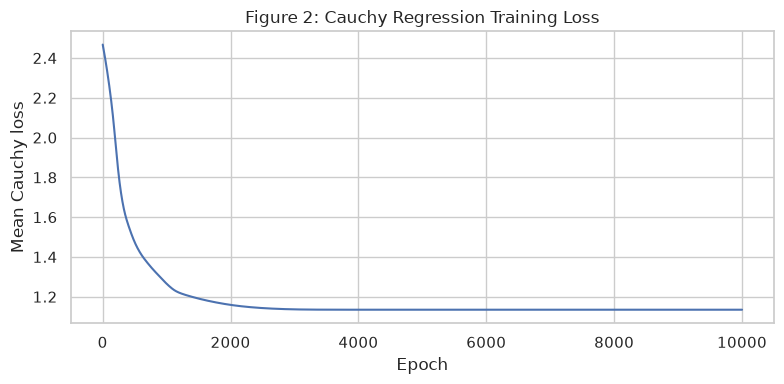

In [6]:
features = ["AT", "V", "AP", "RH"]

X = df[features].to_numpy(dtype=np.float64)
y = df["PE"].to_numpy(dtype=np.float64)

model = CauchyRegression(
    learning_rate=0.01,
    epochs=10000,
    c=1.0,
)

model.fit(X, y)
y_pred = model.predict(X)

print("Training completed.")
print(f"Final mean Cauchy loss: {model.final_loss_:.6f}")

display(pd.DataFrame({
    "Actual PE (MW)": y[:5],
    "Predicted PE (MW)": y_pred[:5],
}))

plt.figure(figsize=(8, 4))
plt.plot(
    np.arange(1, len(model.loss_history) + 1),
    model.loss_history,
)
plt.xlabel("Epoch")
plt.ylabel("Mean Cauchy loss")
plt.title("Figure 2: Cauchy Regression Training Loss")
plt.tight_layout()
plt.show()

### 5.3 Fitted Coefficients

The coefficients below are expressed in the original feature units
and correspond to the model

$$
\widehat{PE}=w_0+w_1AT+w_2V+w_3AP+w_4RH.
$$

In [7]:
coefficient_table = pd.DataFrame({
    "Parameter": ["w0", "w1", "w2", "w3", "w4"],
    "Term": ["Intercept", "AT", "V", "AP", "RH"],
    "Estimated coefficient": np.r_[model.intercept_, model.coef_],
})

display(coefficient_table.round(6))

,Parameter,Term,Estimated coefficient
0,w0,Intercept,511.559333
1,w1,AT,-2.082566
2,w2,V,-0.235827
3,w3,AP,0.007403
4,w4,RH,-0.154875


The fitted model, with coefficients rounded to six decimal places, is

$$
\widehat{PE}
=511.559333
-2.082566\,AT
-0.235827\,V
+0.007403\,AP
-0.154875\,RH.
$$

Each slope represents the change in predicted PE (MW) for a one-unit
increase in that predictor, holding the other predictors constant.

### 5.4 Final Loss Value

The final mean Cauchy loss, using $c=1$, is

$$
\boxed{L=1.134774.}
$$

The training-loss curve decreases and appears to stabilize after
approximately 3,000 epochs. Training was run for 10,000 epochs
with a learning rate of 0.01.

This value is the mean Cauchy loss on the fitted dataset, not
mean squared error or a test-set loss.

### 5.5 Interpretation of the 95% Confidence Intervals

A 95% confidence interval gives a range of plausible values for a
population regression coefficient, under the assumptions of the
estimation method.

If we repeatedly collected samples and constructed intervals using
the same procedure, approximately 95% of those intervals would
contain the true coefficient.

For each predictor, the interval describes uncertainty in its
coefficient while accounting for the other predictors in the model.

- A narrow interval indicates a more precise coefficient estimate.
- A wide interval indicates greater uncertainty.
- An interval entirely above zero supports a positive association.
- An interval entirely below zero supports a negative association.
- An interval containing zero means that a zero coefficient cannot
  be rejected by the corresponding two-sided test at the 5% level.

The fitted model uses Cauchy loss, so ordinary least-squares
standard-error formulas should not be applied directly. Numerical
confidence intervals will be obtained from the Cauchy likelihood
implementation in Section 5.7 and interpreted under its assumptions.

### 5.6 Residual Plots

Following the question, the residuals are defined as

$$
r_i=\hat{y}_i-y_i.
$$

Positive residuals indicate overprediction, while negative residuals
indicate underprediction. We plot these residuals against each of
the four predictors to examine patterns and changes in spread.

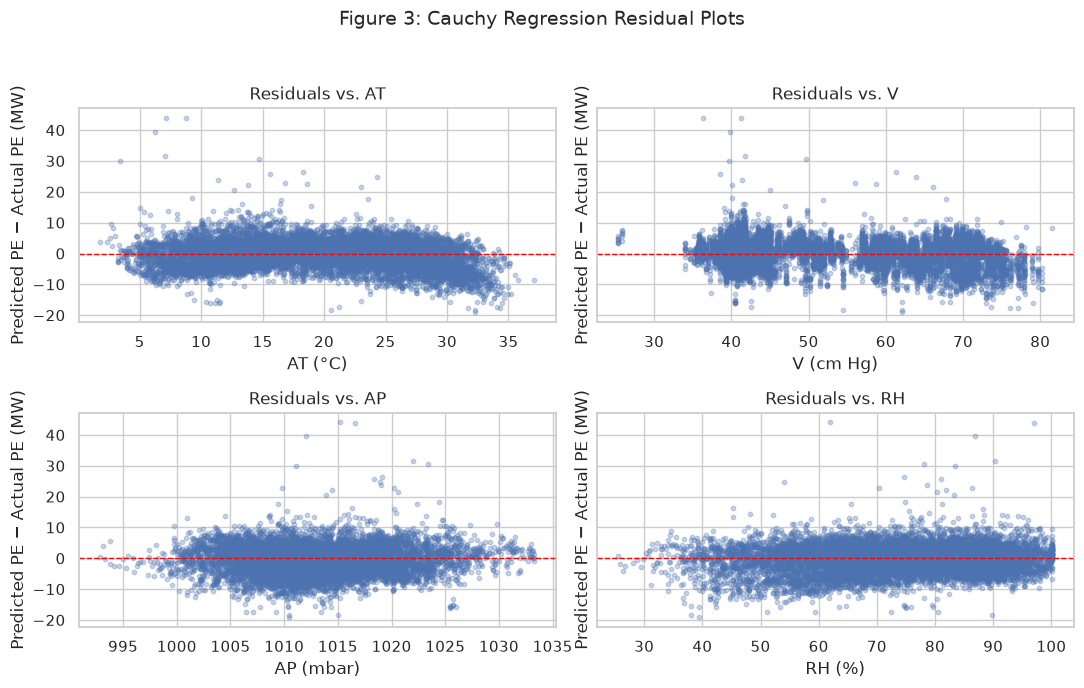

In [8]:
residuals = y_pred - y

axis_labels = [
    "AT (°C)",
    "V (cm Hg)",
    "AP (mbar)",
    "RH (%)",
]

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)

for j, ax in enumerate(axes.flat):
    ax.scatter(
        X[:, j],
        residuals,
        s=10,
        alpha=0.3,
    )
    ax.axhline(0, color="red", linestyle="--", linewidth=1)
    ax.set_xlabel(axis_labels[j])
    ax.set_ylabel("Predicted PE − Actual PE (MW)")
    ax.set_title(f"Residuals vs. {features[j]}")

fig.suptitle("Figure 3: Cauchy Regression Residual Plots", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

**Conclusion from the residual plots:**

Most residuals lie near zero, but they are not distributed randomly
with a uniform spread across all predictor values.

- **AT:** The residuals show some curvature and become more negative
  at high temperatures, indicating a tendency to underpredict PE
  in that region.
- **V:** Clusters and changes in residual location and spread are
  visible, suggesting that the linear model does not capture all
  relationships involving exhaust vacuum.
- **AP:** No strong overall linear trend is apparent, although the
  residual spread varies across the observed pressure range.
- **RH:** The residual distribution changes with humidity, with a
  wider negative spread at some intermediate humidity values.

Several large positive residuals exceed 30 MW, indicating substantial
overprediction for a small number of observations.

Overall, the patterns suggest remaining nonlinear structure and
possible nonconstant error variance. Cauchy loss reduces the influence
of large errors during fitting, but it does not eliminate those errors
or guarantee that a linear model captures every relationship.

### 5.7 Cauchy Regression Using statsmodels (Bonus: 20 Points)

I implement an alternative Cauchy regression model by defining
`CauchyModel` as a subclass of `GenericLikelihoodModel` from statsmodels.

The model uses the same four predictors—AT, V, AP, and RH—to predict
PE, with the Cauchy scale fixed at \(c = 1\).

The implementation estimates the regression coefficients by maximum
likelihood and provides approximate 95% confidence intervals.

In [9]:
from statsmodels.base.model import GenericLikelihoodModel


class CauchyModel(GenericLikelihoodModel):
    def __init__(self, endog, exog, c=1.0, **kwargs):
        self.c = float(c)
        if self.c <= 0:
            raise ValueError("c must be positive.")

        super().__init__(endog, exog, **kwargs)

    def nloglikeobs(self, params):
        # Predicted output and residual for each observation.
        predictions = self.exog @ params
        residuals = self.endog - predictions

        # Negative log-likelihood of a Cauchy distribution.
        return (
            np.log(np.pi * self.c)
            + np.log1p((residuals / self.c) ** 2)
        )


print("CauchyModel class defined successfully.")

CauchyModel class defined successfully.


In [10]:
# Standardize the predictors to improve numerical stability.
x_mean_sm = X.mean(axis=0)
x_scale_sm = X.std(axis=0)
X_scaled_sm = (X - x_mean_sm) / x_scale_sm

# Add a column of ones for the intercept.
X_design_sm = np.column_stack([
    np.ones(len(X)),
    X_scaled_sm
])

# Use the previous fit as starting values, in standardized units.
start_params_sm = np.r_[
    model.intercept_ + x_mean_sm @ model.coef_,
    model.coef_ * x_scale_sm
]

# Fit the alternative statsmodels implementation.
cauchy_sm = CauchyModel(y, X_design_sm, c=1.0)

result_sm = cauchy_sm.fit(
    start_params=start_params_sm,
    method="bfgs",
    maxiter=10000,
    gtol=1e-6,
    disp=False
)

# Calculate predictions and the same loss used in Section 5.2.
y_pred_sm = X_design_sm @ result_sm.params
loss_sm = np.mean(
    0.5 * np.log1p((y - y_pred_sm) ** 2)
)

print("Converged:", result_sm.mle_retvals["converged"])
print(f"Final mean Cauchy loss: {loss_sm:.6f}")

Converged: True
Final mean Cauchy loss: 1.134774


In [11]:
from scipy.stats import norm

# Transform standardized coefficients back to original units.
transform = np.eye(X.shape[1] + 1)
transform[0, 1:] = -x_mean_sm / x_scale_sm
transform[1:, 1:] = np.diag(1.0 / x_scale_sm)

params_original = transform @ result_sm.params

# Transform the full covariance matrix, including the intercept.
cov_original = (
    transform @ result_sm.cov_params() @ transform.T
)
standard_errors = np.sqrt(np.diag(cov_original))

# Approximate 95% confidence intervals.
z_critical = norm.ppf(0.975)
ci_lower = params_original - z_critical * standard_errors
ci_upper = params_original + z_critical * standard_errors

results_table = pd.DataFrame({
    "Term": ["Intercept"] + features,
    "Coefficient": params_original,
    "Standard error": standard_errors,
    "95% CI lower": ci_lower,
    "95% CI upper": ci_upper
})

display(results_table.round(6))

,Term,Coefficient,Standard error,95% CI lower,95% CI upper
0,Intercept,511.559333,8.427804,495.041140,528.077526
1,AT,-2.082566,0.012918,-2.107885,-2.057247
2,V,-0.235827,0.005943,-0.247476,-0.224179
3,AP,0.007403,0.008196,-0.008661,0.023466
4,RH,-0.154875,0.003510,-0.161754,-0.147995


**Interpretation of the statsmodels results**

The statsmodels implementation converged and produced coefficients
matching the PyTorch estimates to six decimal places. Both implementations
gave a final mean Cauchy loss of 1.134774.

Holding the other predictors fixed:

- **AT:** The approximate 95% confidence interval is
  [-2.107885, -2.057247]. Higher temperature is associated with lower PE.
- **V:** The interval is [-0.247476, -0.224179]. Higher exhaust vacuum
  is associated with lower PE.
- **AP:** The interval is [-0.008661, 0.023466]. Because it includes
  zero, the atmospheric-pressure coefficient is not statistically
  significant at the 5% level under this model.
- **RH:** The interval is [-0.161754, -0.147995]. Higher relative
  humidity is associated with lower PE after accounting for the
  other predictors.

These are approximate, model-based confidence intervals assuming
independent Cauchy errors with fixed scale c = 1. The patterns in the
residual plots suggest that these assumptions may not fully describe
the data, so the intervals should be interpreted cautiously.

## 6. Logistic Regression

### 6.1 Dataset and Classification Goal

I use the Steel Industry Energy Consumption dataset from the UCI
Machine Learning Repository. It contains real measurements collected
from DAEWOO Steel Co. Ltd. in Gwangyang, South Korea.

The dataset contains 35,040 observations, and its CSV file is
approximately 2.6 MB. It meets the assignment requirements of at
least 5,000 samples, at least three features, and a size below 1 GB.

The goal is to classify whether an observation belongs to the
Maximum Load category using electrical measurements.

**Target labels**

The original `Load_Type` column contains three categories. I group
them into two classes for binary logistic regression:

- **1 — Maximum Load**
- **0 — Light Load or Medium Load**

This grouping uses the existing labels from real observations;
no synthetic data are generated.

**Selected predictors**

| Feature | Description | Unit |
|:---|:---|:---|
| `Usage_kWh` | Electrical energy consumption | kWh |
| `Lagging_Current_Reactive.Power_kVarh` | Lagging reactive energy | kVarh |
| `Leading_Current_Reactive_Power_kVarh` | Leading reactive energy | kVarh |
| `Lagging_Current_Power_Factor` | Lagging power factor | % |
| `Leading_Current_Power_Factor` | Leading power factor | % |

This task identifies the recorded load category from measurements
for the same observation; it does not forecast future load.

I implement binary logistic regression in PyTorch using binary
cross-entropy and stochastic gradient descent. I check class
imbalance and assess performance on a separate test set.

**Dataset source:**  
https://archive.ics.uci.edu/dataset/851/steel+industry+energy+consumption

**Alternate source:** 
Google drive: https://drive.google.com/file/d/1En9C8OkkglfHB79oUSw6CxIgE_tGO2bL/view?usp=drive_link

**Reference:**  
V E, S., Shin, C., & Cho, Y. (2021).
Steel Industry Energy Consumption [Dataset].
UCI Machine Learning Repository.
https://doi.org/10.24432/C52G8C

### 6.2 Downloading and Inspecting the Dataset

To obtain the dataset manually:

1. Open the UCI dataset page linked in Section 6.1.
2. Click **Download**.
3. Extract `Steel_industry_data.csv` from the downloaded ZIP archive.

The following cell downloads the same archive directly from UCI
and reads the CSV into pandas.

Only the five electrical predictors listed in Section 6.1 will
be used as model inputs. The `Load_Type` column supplies the labels.
The remaining columns are not used as predictors.

In [12]:
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

steel_url = (
    "https://archive.ics.uci.edu/static/public/851/"
    "steel+industry+energy+consumption.zip"
)

with urlopen(steel_url, timeout=60) as response:
    archive_bytes = response.read()

with ZipFile(BytesIO(archive_bytes)) as archive:
    csv_bytes = archive.read("Steel_industry_data.csv")

steel_df = pd.read_csv(BytesIO(csv_bytes))

print("Dataset shape:", steel_df.shape)
print(f"CSV size: {len(csv_bytes) / 1_000_000:.2f} MB")
print("\nColumn names:")
print(steel_df.columns.tolist())

display(steel_df.head())

print("\nMissing values per column:")
print(steel_df.isna().sum())

print("\nOriginal load categories:")
print(steel_df["Load_Type"].value_counts())

print("\nDuplicate rows:", steel_df.duplicated().sum())

Dataset shape: (35040, 11)
CSV size: 2.73 MB

Column names:
['date', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'WeekStatus', 'Day_of_week', 'Load_Type']


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load



Missing values per column:
date                                    0
Usage_kWh                               0
Lagging_Current_Reactive.Power_kVarh    0
Leading_Current_Reactive_Power_kVarh    0
CO2(tCO2)                               0
Lagging_Current_Power_Factor            0
Leading_Current_Power_Factor            0
NSM                                     0
WeekStatus                              0
Day_of_week                             0
Load_Type                               0
dtype: int64

Original load categories:
Load_Type
Light_Load      18072
Medium_Load      9696
Maximum_Load     7272
Name: count, dtype: int64

Duplicate rows: 0


### 6.3 Feature Selection and Class Imbalance

I select the five electrical predictors described in Section 6.1.
I encode Maximum Load as class 1 and combine Light Load and Medium
Load into class 0.

The dataset has no missing values or duplicate rows, so no rows
are removed during these checks.

I calculate the count and percentage of each binary class to
check for class imbalance.

In [13]:
logit_features = [
    "Usage_kWh",
    "Lagging_Current_Reactive.Power_kVarh",
    "Leading_Current_Reactive_Power_kVarh",
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor"
]

label_mapping = {
    "Light_Load": 0,
    "Medium_Load": 0,
    "Maximum_Load": 1
}

X_logit = steel_df[logit_features].copy()
y_logit = steel_df["Load_Type"].map(label_mapping)

if y_logit.isna().any():
    raise ValueError("An unexpected load category was found.")

y_logit = y_logit.astype(int)

class_counts = y_logit.value_counts().reindex([0, 1], fill_value=0)

class_table = pd.DataFrame({
    "Class": [0, 1],
    "Meaning": ["Light or Medium Load", "Maximum Load"],
    "Count": class_counts.to_numpy(),
    "Percentage (%)": (
        100 * class_counts / len(y_logit)
    ).to_numpy()
})

display(class_table.round(2))

print("Selected feature shape:", X_logit.shape)
print(
    "Majority-class baseline accuracy:",
    f"{class_counts.max() / len(y_logit):.2%}"
)

,Class,Meaning,Count,Percentage (%)
0,0,Light or Medium Load,27768,79.25
1,1,Maximum Load,7272,20.75


Selected feature shape: (35040, 5)
Majority-class baseline accuracy: 79.25%


**Class imbalance assessment**

Class 0 (Light or Medium Load) contains 27,768 observations
(79.25%), while class 1 (Maximum Load) contains 7,272 observations
(20.75%). Therefore, the binary dataset is imbalanced.

Always predicting class 0 would achieve 79.25% accuracy on the
full dataset, but would identify none of the Maximum Load cases.
Consequently, accuracy alone is insufficient for evaluating the model.

I will also report precision, recall, F1-score, a confusion matrix,
and ROC-AUC on the test set, paying particular attention to the
model's ability to identify Maximum Load observations.

### 6.4 Training, Validation, and Test Sets

I sort the observations by timestamp and divide them chronologically:

- First 70%: training set for learning the model parameters.
- Next 15%: validation set for checking training and choosing settings.
- Final 15%: test set reserved for final evaluation.

A chronological split avoids randomly mixing nearby observations
between the training and test sets.

The timestamp determines the split but is not a model input.
Feature scaling will use statistics calculated from the training
set only.

In [14]:
# Sort row indices by timestamp.
timestamps = pd.to_datetime(
    steel_df["date"],
    format="%d/%m/%Y %H:%M"
)
time_order = timestamps.sort_values().index

X_ordered = X_logit.loc[time_order].reset_index(drop=True)
y_ordered = y_logit.loc[time_order].reset_index(drop=True)

# Split into 70% training, 15% validation, and 15% test.
n_samples = len(X_ordered)
train_end = int(0.70 * n_samples)
val_end = int(0.85 * n_samples)

X_train_logit = X_ordered.iloc[:train_end].copy()
X_val_logit = X_ordered.iloc[train_end:val_end].copy()
X_test_logit = X_ordered.iloc[val_end:].copy()

y_train_logit = y_ordered.iloc[:train_end].copy()
y_val_logit = y_ordered.iloc[train_end:val_end].copy()
y_test_logit = y_ordered.iloc[val_end:].copy()

# Check sample counts and class proportions in each set.
split_table = pd.DataFrame([
    {
        "Set": name,
        "Samples": len(labels),
        "Class 0": int((labels == 0).sum()),
        "Class 1": int((labels == 1).sum()),
        "Maximum Load (%)": 100 * labels.mean()
    }
    for name, labels in [
        ("Training", y_train_logit),
        ("Validation", y_val_logit),
        ("Test", y_test_logit)
    ]
])

display(split_table.round(2))

,Set,Samples,Class 0,Class 1,Maximum Load (%)
0,Training,24528,19337,5191,21.16
1,Validation,5256,4207,1049,19.96
2,Test,5256,4224,1032,19.63


### 6.5 Feature Standardization

The electrical predictors have different units and numerical scales.
I standardize each feature using

$$
z_j = \frac{x_j-\mu_{j,\mathrm{train}}}
{\sigma_{j,\mathrm{train}}}.
$$

The mean and standard deviation are calculated from the training
set only. The same values are then applied to the validation and
test sets, preventing information from these sets from influencing
the scaling.

Standardization helps stochastic gradient descent train efficiently.

In [15]:
# Calculate scaling statistics using only the training set.
logit_mean = X_train_logit.mean()
logit_scale = X_train_logit.std(ddof=0)

# Avoid division by zero if a feature is constant.
logit_scale = logit_scale.replace(0, 1.0)

X_train_scaled = (
    (X_train_logit - logit_mean) / logit_scale
).to_numpy(dtype=np.float64)

X_val_scaled = (
    (X_val_logit - logit_mean) / logit_scale
).to_numpy(dtype=np.float64)

X_test_scaled = (
    (X_test_logit - logit_mean) / logit_scale
).to_numpy(dtype=np.float64)

scaling_check = pd.DataFrame({
    "Feature": logit_features,
    "Training mean after scaling": X_train_scaled.mean(axis=0),
    "Training std after scaling": X_train_scaled.std(axis=0)
})

display(scaling_check.round(6))

,Feature,Training mean after scaling,Training std after scaling
0,Usage_kWh,-0.0,1.0
1,Lagging_Current_Reactive.Power_kVarh,-0.0,1.0
2,Leading_Current_Reactive_Power_kVarh,0.0,1.0
3,Lagging_Current_Power_Factor,0.0,1.0
4,Leading_Current_Power_Factor,-0.0,1.0


### 6.6 Logistic Regression Model and Training Method

Following the lecture, the model calculates a linear score from
the five standardized predictors:

$$
z_i = b + \mathbf{w}^{T}\mathbf{x}_i.
$$

The sigmoid function converts this score into the estimated
probability of Maximum Load:

$$
\hat{p}_i = \frac{1}{1+\exp(-z_i)}.
$$

The model minimizes binary cross-entropy:

$$
J(\mathbf{w},b)
=
-\frac{1}{N}\sum_{i=1}^{N}
\left[
y_i\log(\hat{p}_i)
+(1-y_i)\log(1-\hat{p}_i)
\right].
$$

I initialize the weights and bias to zero and train using stochastic
gradient descent. For a single training observation, the updates are

$$
\mathbf{w}
\leftarrow
\mathbf{w}+\eta(y_i-\hat{p}_i)\mathbf{x}_i,
$$

$$
b \leftarrow b+\eta(y_i-\hat{p}_i),
$$

where $\eta$ is the learning rate.

For prediction, a probability of at least 0.5 is assigned to class 1
(Maximum Load); otherwise, the prediction is class 0.

**Package implementation (Bonus: 10 Points)**

I implement the model in `src/tornadochildd/model/logit.py`
and demonstrate its use by importing the class into this notebook.

In [16]:
import importlib
import inspect

importlib.invalidate_caches()

from tornadochildd.model.logit import LogisticRegression

print("LogisticRegression imported successfully.")
print("Loaded from:", inspect.getfile(LogisticRegression))

LogisticRegression imported successfully.
Loaded from: /home/md-aslam-hossain/tornadochildd/.venv/lib/python3.12/site-packages/tornadochildd/model/logit.py


### 6.7 Model Training

I train the model using a learning rate of 0.001 for 50 epochs,
with one training observation per SGD update. The training
observations are shuffled each epoch using a fixed seed of 42.

Binary cross-entropy is calculated using `BCEWithLogitsLoss`,
which combines sigmoid and cross-entropy in a numerically stable
form.

I record training and validation losses after each epoch and
retain the parameters from the epoch with the lowest validation
loss. The test set is reserved for final evaluation.

In [17]:
logit_model = LogisticRegression(
    learning_rate=0.001,
    epochs=50,
    seed=42
)

logit_model.fit(
    X_train_scaled,
    y_train_logit,
    X_val_scaled,
    y_val_logit
)

print("\nTraining completed.")
print("Selected epoch:", logit_model.best_epoch_)
print(
    "Best validation cross-entropy:",
    f"{logit_model.best_val_loss_:.6f}"
)

/home/md-aslam-hossain/tornadochildd/.venv/lib/python3.12/site-packages/tornadochildd/model/logit.py:20: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  X_train = torch.as_tensor(


Epoch 1/50 | Train loss: 0.359779 | Validation loss: 0.325426
Epoch 10/50 | Train loss: 0.332747 | Validation loss: 0.312967
Epoch 20/50 | Train loss: 0.329695 | Validation loss: 0.315414
Epoch 30/50 | Train loss: 0.329062 | Validation loss: 0.316499
Epoch 40/50 | Train loss: 0.328929 | Validation loss: 0.316832
Epoch 50/50 | Train loss: 0.328926 | Validation loss: 0.317345

Training completed.
Selected epoch: 7
Best validation cross-entropy: 0.312486


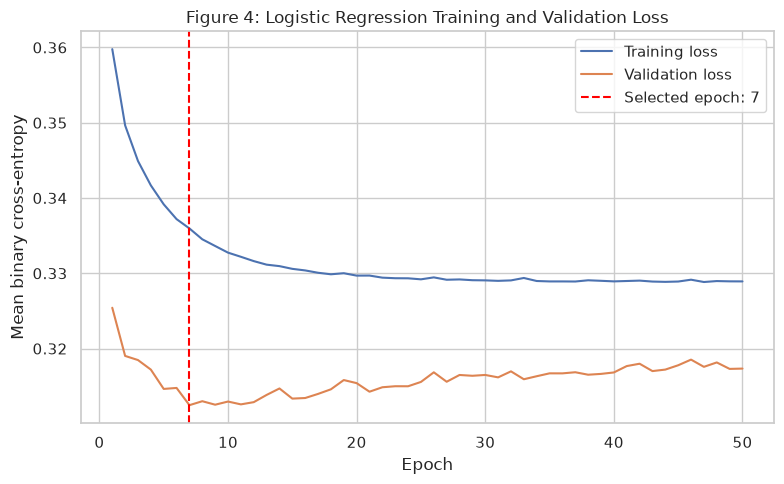

In [18]:
epoch_numbers = np.arange(
    1, len(logit_model.train_loss_history) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    logit_model.train_loss_history,
    label="Training loss"
)
plt.plot(
    epoch_numbers,
    logit_model.val_loss_history,
    label="Validation loss"
)
plt.axvline(
    logit_model.best_epoch_,
    color="red",
    linestyle="--",
    label=f"Selected epoch: {logit_model.best_epoch_}"
)

plt.xlabel("Epoch")
plt.ylabel("Mean binary cross-entropy")
plt.title("Figure 4: Logistic Regression Training and Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation of the learning curves**

The training cross-entropy decreases from 0.359779 to 0.328926
and becomes nearly constant toward the end of training.

The validation loss reaches its minimum of 0.312486 at epoch 7.
Afterward, it fluctuates and gradually increases, although the
training loss continues to decrease. Further training therefore
does not improve performance on the validation set.

I retain the parameters from epoch 7 for final evaluation.
This selection uses only the validation set; the test set has
not been used to choose the model.

The validation loss is lower than the training loss. This is
possible because the two sets contain different observations
from different time periods; it does not by itself indicate
an implementation error.

### 6.8 Test-Set Performance

I evaluate the selected model on the held-out test set using a
classification threshold of 0.5.

I report accuracy, precision, recall, F1-score, and ROC-AUC.
ROC-AUC is calculated from predicted probabilities.

For comparison, I also evaluate a baseline that always predicts
the majority class identified in the training set.

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Evaluate the model selected using validation loss.
test_probabilities = logit_model.predict_proba(X_test_scaled)
test_predictions = logit_model.predict(
    X_test_scaled, threshold=0.5
)

# Choose the baseline class using training labels only.
majority_class = int(y_train_logit.mode().iloc[0])
baseline_predictions = np.full(
    len(y_test_logit), majority_class
)

test_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision (Maximum Load)",
        "Recall (Maximum Load)",
        "F1-score (Maximum Load)",
        "ROC-AUC",
        "Majority-class baseline accuracy"
    ],
    "Value": [
        accuracy_score(y_test_logit, test_predictions),
        precision_score(
            y_test_logit, test_predictions, zero_division=0
        ),
        recall_score(
            y_test_logit, test_predictions, zero_division=0
        ),
        f1_score(
            y_test_logit, test_predictions, zero_division=0
        ),
        roc_auc_score(y_test_logit, test_probabilities),
        accuracy_score(y_test_logit, baseline_predictions)
    ]
})

display(test_metrics.round(6))

print("\nClassification report:")
print(classification_report(
    y_test_logit,
    test_predictions,
    labels=[0, 1],
    target_names=["Light or Medium Load", "Maximum Load"],
    digits=4,
    zero_division=0
))

,Metric,Value
0,Accuracy,0.765221
1,Precision (Maximum Load),0.343168
2,Recall (Maximum Load),0.214147
3,F1-score (Maximum Load),0.263723
4,ROC-AUC,0.683933
5,Majority-class baseline accuracy,0.803653



Classification report:
                      precision    recall  f1-score   support

Light or Medium Load     0.8242    0.8999    0.8603      4224
        Maximum Load     0.3432    0.2141    0.2637      1032

            accuracy                         0.7652      5256
           macro avg     0.5837    0.5570    0.5620      5256
        weighted avg     0.7297    0.7652    0.7432      5256



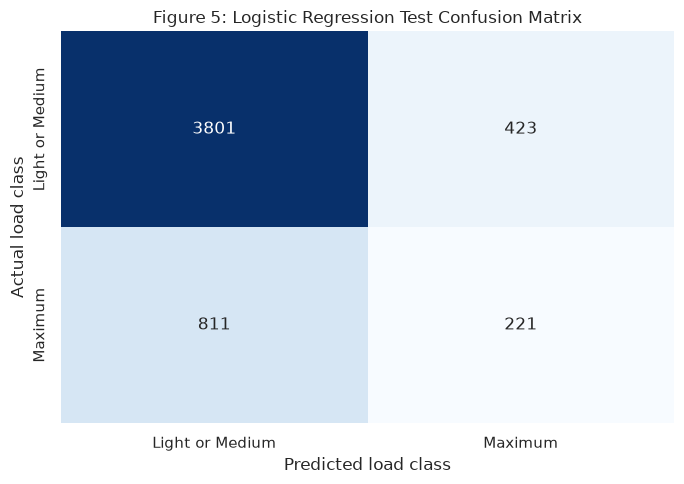

True negatives: 3801
False positives: 423
False negatives: 811
True positives: 221


In [20]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test_logit, test_predictions, labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Light or Medium", "Maximum"],
    yticklabels=["Light or Medium", "Maximum"]
)

plt.xlabel("Predicted load class")
plt.ylabel("Actual load class")
plt.title("Figure 5: Logistic Regression Test Confusion Matrix")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)

**Interpretation of the confusion matrix**

At the classification threshold of 0.5, the model produces:

- **3,801 true negatives:** Light or Medium Load correctly classified.
- **423 false positives:** Light or Medium Load classified as Maximum Load.
- **811 false negatives:** Maximum Load classified as Light or Medium Load.
- **221 true positives:** Maximum Load correctly classified.

Maximum Load recall is 221/1,032 = 21.41%, meaning that the model
misses 78.59% of the actual Maximum Load observations.

Its accuracy of 76.52% is below the majority-class baseline of
80.37%. Although the baseline detects no Maximum Load cases,
the trained model's low recall and precision show that it is
not reliable for identifying Maximum Load at this threshold.

These results demonstrate why accuracy alone is insufficient
for assessing this imbalanced classification problem.

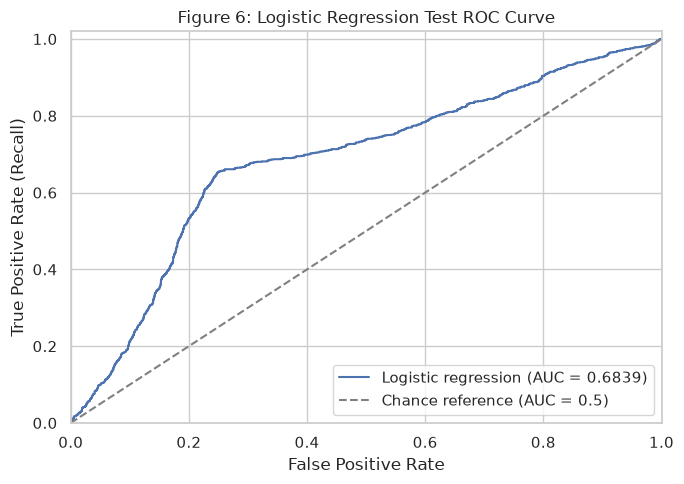

In [21]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(
    y_test_logit, test_probabilities
)
test_auc = roc_auc_score(
    y_test_logit, test_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic regression (AUC = {test_auc:.4f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    color="gray",
    linestyle="--",
    label="Chance reference (AUC = 0.5)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Figure 6: Logistic Regression Test ROC Curve")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation of the ROC curve**

The test ROC-AUC is 0.6839, indicating better discrimination
than random ranking (AUC = 0.5), but substantial overlap remains
between the two classes. AUC measures ranking ability and should
not be interpreted as classification accuracy.

Lowering the classification threshold would increase recall,
but would also increase false positives. Any threshold tuning
should use the validation set rather than the test set.

**Conclusion**

The custom PyTorch logistic regression model was trained using
binary cross-entropy and stochastic gradient descent. The
parameters from epoch 7 were selected using validation loss.

On the chronological test set, the model achieved 76.52% accuracy,
21.41% Maximum Load recall, and an ROC-AUC of 0.6839. These results
show limited effectiveness for identifying Maximum Load with the
five selected electrical predictors.

The evaluation accounts for class imbalance by reporting
class-specific metrics and comparing accuracy with a majority-class
baseline. The model was implemented in `model/logit.py`, imported
from the package, and used for training and prediction.